# Prot2GO Evaluation with CAFA5 Test Set

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO

from prot2go.data import ppi_data

# Define folder paths
base_dir = Path("/home/clever/projects/prot2go/")
data_dir = base_dir / "raw"


## Filter Training and Testing by Size and Knowledge

In [2]:
# Min and max protein sequences lengths
min_length = 0
max_length = 50000

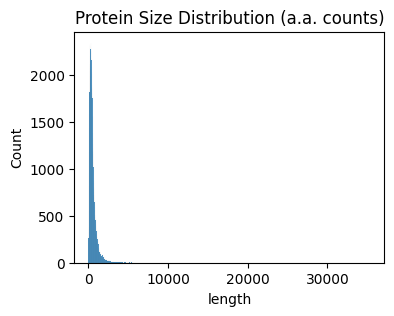

Sequences df dims: (142246, 3)
   uniprot_id                                           sequence  length
0  A0A8I5ZUN3  MTTQAPTFTQPLQSVVVLEGSAATFEAHISGSPVPEVSWFRDGQVI...   35375
1      A2ASS6  MTTQAPMFTQPLQSVVVLEGSTATFEAHVSGSPVPEVSWFRDGQVI...   35213
2      Q8WZ42  MTTQAPTFTQPLQSVVVLEGSTATFEAHISGFPVPEVSWFRDGQVI...   34350
3      A5X6X5  MTTQAPTFTQPLQSVVALEGSAATFEAQVSGNPVPEVSWFRDGQVL...   32757
4      G1K2X0  MSTQAPTFTQPLQSVVALEGSAATFEAQVSGNPVPEVSWFRDGQVL...   29152
Total number of sequences: 142246


In [3]:
# Get train annotated sequences
train_filtered_df = ppi_data.process_cafa_sequences(
    data_folder=data_dir,
    dataset="train",
    filter_annotated=True,
    min_length=min_length,
    max_length=max_length,
)  # All proteins in the training data are annotated

print(f"Total number of sequences: {len(train_filtered_df)}")

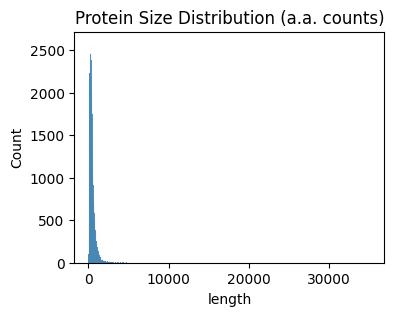

Sequences df dims: (141865, 3)
  uniprot_id                                           sequence  length
0     A2ASS6  MTTQAPMFTQPLQSVVVLEGSTATFEAHVSGSPVPEVSWFRDGQVI...   35213
1     Q8WZ42  MTTQAPTFTQPLQSVVVLEGSTATFEAHISGFPVPEVSWFRDGQVI...   34350
2     G4SLH0  MEGNEKKGGGLPPTQQRHLNIDTTVGGSISQPVSPSMSYSTDRETV...   18562
3     Q9I7U4  MQRQNPNPYQQQNQQHQQVQQFSSQEYSHSSQEQHQEQRISRTEQH...   18141
4     Q8WXI7  MLKPSGLPGSSSPTRSLMTGSRSTKATPEMDSGLTGATLSPKTSTG...   14507

Number of unique identifiers: 141864


In [4]:
# Get test annotated sequences (limited and no knowledge)

test_df = ppi_data.process_cafa_sequences(
    data_folder=data_dir,
    dataset="test",
    filter_annotated=False,  # no annotation filtering
    min_length=min_length,
    max_length=max_length,
)

print(f"\nNumber of unique identifiers: {len(test_df["uniprot_id"].unique())}")

In [5]:
# Check duplicated identifiers
display(test_df[test_df.duplicated(keep=False)])

# Remove duplicates
test_df.drop_duplicates(inplace=True)
test_df.reset_index(drop=True, inplace=True)

print(
    f"\nNumber of entries after removing duplicates: {len(test_df)}"
)

,uniprot_id,sequence,length
15848,A0A1D6E0S8,MPSRSPACRPRGRNRRSAADAVARPLALALILVSTLPRAAHSQDLA...,856
15877,A0A1D6E0S8,MPSRSPACRPRGRNRRSAADAVARPLALALILVSTLPRAAHSQDLA...,856



Number of entries after removing duplicates: 141864


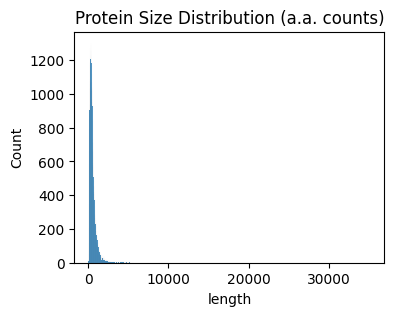

Sequences df dims: (73653, 3)
  uniprot_id                                           sequence  length
0     A2ASS6  MTTQAPMFTQPLQSVVVLEGSTATFEAHVSGSPVPEVSWFRDGQVI...   35213
1     Q8WZ42  MTTQAPTFTQPLQSVVVLEGSTATFEAHISGFPVPEVSWFRDGQVI...   34350
2     G4SLH0  MEGNEKKGGGLPPTQQRHLNIDTTVGGSISQPVSPSMSYSTDRETV...   18562
3     Q9I7U4  MQRQNPNPYQQQNQQHQQVQQFSSQEYSHSSQEQHQEQRISRTEQH...   18141
4     Q8WXI7  MLKPSGLPGSSSPTRSLMTGSRSTKATPEMDSGLTGATLSPKTSTG...   14507

Number of unique identifiers: 73653


In [6]:
# Get test set with at least 1 annotation (limited knowledge)

test_lk_df = ppi_data.process_cafa_sequences(
    data_folder=data_dir,
    dataset="test",
    filter_annotated=True,
    min_length=min_length,
    max_length=max_length,
)

print(f"\nNumber of unique identifiers: {len(test_lk_df["uniprot_id"].unique())}")

In [7]:
# Get test set without annotations

test_nk_df = test_df[~test_df.isin(test_lk_df.to_dict(orient="list")).all(axis=1)]
test_nk_df.reset_index(drop=True, inplace=True)

print(f"\nNumber of unique identifiers: {len(test_nk_df['uniprot_id'].unique())}")
print(f"Test no knowledge dimension: {test_nk_df.shape}")
test_nk_df.head()


Number of unique identifiers: 68211
Test no knowledge dimension: (68211, 3)


,uniprot_id,sequence,length
0,I1SAJ7,MLAGRPPPPVSSLVHDMIAQRARKQPDAEASISWDTTMTYADLDEL...,11197
1,Q54CU4,MGTIKTKFKNNYLKNSYLFIIYIILFNLVIGIANSEALGVPSKIRP...,11103
2,C6KTB7,MKDLYSLYEDISENDKIIISEKLKNLLNYFQDKNKSYVSEFVVVSR...,10287
3,Q8I3Z1,MDCNFFEEDGSSSMNQTNGISKENVSEKVYSEDDKNTSCYVSYSSH...,10061
4,A0A098D1P1,MALLNGKSTLPNGHNSSIESPNGYTEHEMPIPSDWQRYLIDIDHAA...,7839


## Checking Data Consistency
- Load Training and Testing Fastas
- Check number of unique identifiers

In [8]:
# Create dictionary with training fasta sequences

filepath = data_dir / "cafa/train_sequences.fasta"
train_dict = {}  # Dictionary Uniprot ID: sequence
for seq_record in SeqIO.parse(filepath, "fasta"):
    train_dict[seq_record.id] = str(seq_record.seq)

print(f"Length of sequences dictionary: {len(train_dict)}")
for key, value in train_dict.items():
    print(f"Uniprot ID: {key}")
    print(f"Sequence: {value}")
    break

Length of sequences dictionary: 142246
Uniprot ID: P20536
Sequence: MNSVTVSHAPYTITYHDDWEPVMSQLVEFYNEVASWLLRDETSPIPDKFFIQLKQPLRNKRVCVCGIDPYPKDGTGVPFESPNFTKKSIKEIASSISRLTGVIDYKGYNLNIIDGVIPWNYYLSCKLGETKSHAIYWDKISKLLLQHITKHVSVLYCLGKTDFSNIRAKLESPVTTIVGYHPAARDRQFEKDRSFEIINVLLELDNKVPINWAQGFIY


In [9]:
# Create dictionary with test fasta sequences

filepath = data_dir /"cafa/test_sequences.fasta"
test_dict = {}  # Dictionary Uniprot ID: sequence
for seq_record in SeqIO.parse(filepath, "fasta"):
    test_dict[seq_record.id] = str(seq_record.seq)
    
print(f"Length of sequences dictionary: {len(test_dict)}")
for key, value in test_dict.items():
    print(f"Uniprot ID: {key}")
    print(f"Sequence: {value}")
    break
    

Length of sequences dictionary: 141864
Uniprot ID: Q9CQV8
Sequence: MTMDKSELVQKAKLAEQAERYDDMAAAMKAVTEQGHELSNEERNLLSVAYKNVVGARRSSWRVISSIEQKTERNEKKQQMGKEYREKIEAELQDICNDVLELLDKYLILNATQAESKVFYLKMKGDYFRYLSEVASGENKQTTVSNSQQAYQEAFEISKKEMQPTHPIRLGLALNFSVFYYEILNSPEKACSLAKTAFDEAIAELDTLNEESYKDSTLIMQLLRDNLTLWTSENQGDEGDAGEGEN


## Spliting Sequencest into "Limited Knowledge" and "No Knowledge" (CAFA5)
- Limited Knowledge: at least one annotation
- No Knowledge: no annotation

In [10]:
# Check overlapping training vs testing sequences

# Get protein ids
train_ids = list(train_dict.keys())
test_ids = list(test_dict.keys())

# Splitting sequences into "Limited Knowledge (lk)" and "No Knowledge (nk)" (CAFA5)
test_lk_ids = set(train_ids) & set(test_ids)
test_nk_ids = set(test_ids) - set(test_lk_ids)

# Split test dictionary
test_lk_dict = {k: train_dict[k] for k in test_lk_ids}
test_nk_dict = {k: test_dict[k] for k in test_nk_ids}

# Assert number of sequences
assert len(test_lk_ids) + len(test_nk_ids) == len(test_dict), "Length mismatch"
assert len(test_lk_ids) + len(test_nk_ids) == len(test_lk_dict) + len(
    test_nk_dict
), "Length mismatch"

print(f"Length of Limited Knowledge dictionary: {len(test_lk_ids)}")
print(f"Length of No Knowledge dictionary: {len(test_nk_dict)}")
print(f"Total number of sequences: {len(test_lk_ids) + len(test_nk_ids)}")

Length of Limited Knowledge dictionary: 73653
Length of No Knowledge dictionary: 68211
Total number of sequences: 141864


### Load Dataset of PPIs without Annotations (DIP human dataset)

In [11]:
dirpath = base_dir / "preprocessed/ppi/human"
filepath = dirpath / "ppi_unknown.csv"

ppi_df = pd.read_csv(filepath)
ppi_df

,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
0,P02593,P35609,physical interaction,coimmunoprecipitation,core,9606,9606
1,Q14205,Q13424,physical interaction,two hybrid,core,9606,9606
2,Q14205,Q13884,physical interaction,coimmunoprecipitation,core,9606,9606
3,P02593,P17677,physical interaction,two hybrid,core,9606,9606
4,P19138,P67870,physical interaction,two hybrid,core,9606,9606
...,...,...,...,...,...,...,...
149,P62988,P21580,direct interaction;deubiquitination reaction,nuclear magnetic resonance;deubiquitinase assa...,core,9606,9606
150,P62988,P50542,physical association,anti tag coimmunoprecipitation;anti bait coimm...,core,9606,9606
151,P62988,Q13200,direct interaction,pull down,core,9606,9606
152,Q9UNZ5,O60341,physical association,pull down,core,9606,9606


In [12]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x))
    for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(
        tuple(sorted(x))
        for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
    )
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat(
    [ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]
).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 185
# of PPIs: 154
# of unique PPIs: 154


### Create Datasets of PPI with Limited and No Knowledge

In [14]:
# Get PPIs of proteins with limited knowledge
ppi_lk_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(test_lk_ids))
    & (ppi_df["uniprot_id_B"].isin(test_lk_ids))
]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = test_lk_df["uniprot_id"].unique()
ppi_lk_df = ppi_lk_df[
    (ppi_lk_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_lk_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]
ppi_lk_df = ppi_lk_df[
    (ppi_lk_df["uniprot_id_A"] != ppi_lk_df["uniprot_id_B"])
]  # Drop self-interactions

ppi_lk_df.dropna(inplace=True)  # Drop unpaired ids
ppi_lk_df.reset_index(drop=True, inplace=True)
ppi_lk_df.to_csv(dirpath / "ppi_lk_test.csv", index=False)

print(f"PPI limited knowledge df shape: {ppi_lk_df.shape}")
print(ppi_lk_df.head().to_markdown())
ppi_lk_df.describe()

PPI limited knowledge df shape: (0, 7)
| uniprot_id_A   | uniprot_id_B   | ppi_type   | detection_method   | confidence   | taxiID_A   | taxiID_B   |
|----------------|----------------|------------|--------------------|--------------|------------|------------|


,taxiID_A,taxiID_B
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


In [15]:
# Get PPIs of proteins with limited knowledge
ppi_nk_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(test_nk_ids))
    & (ppi_df["uniprot_id_B"].isin(test_nk_ids))
]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = test_lk_df["uniprot_id"].unique()
ppi_nk_df = ppi_nk_df[
    (ppi_nk_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_nk_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]
ppi_nk_df = ppi_nk_df[
    (ppi_nk_df["uniprot_id_A"] != ppi_nk_df["uniprot_id_B"])
]  # Drop self-interactions

ppi_nk_df.dropna(inplace=True)  # Drop unpaired ids
ppi_nk_df.reset_index(drop=True, inplace=True)
ppi_nk_df.to_csv(dirpath / "ppi_lk_test.csv", index=False)

print(f"PPI limited knowledge df shape: {ppi_nk_df.shape}")
print(ppi_nk_df.head().to_markdown())
ppi_nk_df.describe()

PPI limited knowledge df shape: (0, 7)
| uniprot_id_A   | uniprot_id_B   | ppi_type   | detection_method   | confidence   | taxiID_A   | taxiID_B   |
|----------------|----------------|------------|--------------------|--------------|------------|------------|


,taxiID_A,taxiID_B
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


## Extract PPI metadata

In [16]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = ppi_df["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
with open(ppi_preproc_dir / "ppi_types.txt", "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of detection methods
methods = ppi_df["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
with open(ppi_preproc_dir / "ppi_methods.txt", "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

NameError: name 'ppi_preproc_dir' is not defined

## Extract nodes and edges to build the PPI graph

In [ ]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

## Extract Largest Connected Component from PPI graph (ensures connectivity)

In [ ]:
ppi_graph = nx.Graph() # Create undirected graph instance
ppi_graph.add_edges_from(ppi_unique_pairs)  # Add edges
cc = list(nx.connected_components(ppi_graph)) # Get connected components
lcc = max(cc, key=len) # Get the largest connected component (LCC)
ppi_graph_lcc = ppi_graph.subgraph(lcc).copy()  # Extract subgraph

# Extract nodes and edges for graph dataset
ppi_nodes = ppi_graph_lcc.nodes()
ppi_edges = list(ppi_graph_lcc.edges())

# print-out basic graph attributes
print(f"# of connected components: {len(cc)}")
print("\nFull PPI graph attributes:")
print(f"# of nodes: {ppi_graph.number_of_nodes()}")
print(f"# of edges: {ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(ppi_graph_lcc)}")

print("\nExtracted PPI graph attributes:")
print(f"# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(ppi_graph_lcc)}")

## Filter-out disconnected components

In [ ]:
# Filter protein-go associations with LCC nodes

# Keep full protein-GO associations for plotting
associations_full = associations_df.copy()

# Remove associations with large proteins
associations_df = associations_df[
    associations_df["uniprot_id"].isin(list(ppi_graph_lcc.nodes()))
].copy()

associations_df = associations_df[
    associations_df["uniprot_id"].isin(filtered_sequences["uniprot_id"].unique())
]
associations_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = ppi_preproc_dir / "associations.tsv"
associations_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_df['uniprot_id'].unique())}")
associations_df.head()

## Create PPI graph

In [ ]:
ppi_data_human = ppi_data.process_protein_embeddings(
    raw_dir, ppi_preproc_dir, associations_df, ppi_edges, ppi_nodes
)

print(f"Average degree: {degree(ppi_data_human.edge_index[0]).mean():.2f}")
ppi_data_human